# Trusted Inspection Cell: a behaviour tree that decides, a local VLM that looks

**Challenge idea:** #2 *Hybrid Logic & VLM Orchestrator* applied to #6 *Camera-based quality & part inspection*, with the
#3 fault-recovery idea in the form of a circuit breaker and a human-review fallback.

An offline part-inspection cell. A `py_trees` **behaviour tree** runs the line: e-stop, image gate, circuit breaker,
decision rules, diverter. A local **vision-language model** (Gemma 3 4B through Ollama) answers one narrow question about
one close-up the tree chose. The model never moves anything. Each answer goes through a deterministic validator,
fixed rules turn validated answers into PASS / REJECT / REVIEW, and every failure falls back to a human.

| Judging area | Where to look in this notebook |
|---|---|
| 1. Deterministic logic & AI handoffs (30) | section 3 (tree + data/control flow), 4 (decisions with traces), 5a (validator), 5d (override) |
| 2. On-device / offline (25) | section 8 (topology, connectivity drops, live local model), 5c (model server down) |
| 3. Impact & execution (25) | sections 4 to 6 (pipeline, failure handling, audit trail, tests), 8 (latency) |
| 4. Writeup & trade-offs (20) | sections 7 and 8 (why this model, prompt design, topology and control structure) |

**Read this first, because it affects how to read the results.** Sections 4 to 7 run with `MockVLM`, a stand-in model that
reads its answer from the *file name*. It is not an inspector. It exists so that every path through the tree
(pass, reject, bad image, garbage answer, timeout, e-stop, dead model) can be exercised in seconds and checked by tests.
Section 8 runs the real model when an Ollama server is reachable, and says so when it is not.

## 1. Setup

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "py_trees>=2.2", "requests", "pytest"], check=False)
import os
os.makedirs("cell", exist_ok=True)
os.makedirs("tests", exist_ok=True)
open("cell/__init__.py", "w").close()

## 2. The code

The project files are written out below so the notebook is self-contained. They are the same files as in the project repo.
`cell/spec.py` (what a good part is and where to look), `cell/validator.py` (what the AI may say) and `cell/tree.py`
(who decides what) are the three worth reading.

In [2]:
%%writefile cell/config.py
"""Every threshold the cell uses, in one place, so an engineer can audit and tune them."""

from dataclasses import dataclass


@dataclass(frozen=True)
class CellConfig:
    # Local model served by Ollama. Nothing leaves this machine.
    model: str = "gemma3:4b"
    ollama_url: str = "http://localhost:11434"
    # Per region. Measured on an 8 GB CPU-only laptop: 12-238 s per close-up (it swaps), so
    # use `run.py --timeout 600` there. With enough RAM or a GPU, 120 s is ample.
    vlm_timeout_s: float = 120.0

    # Image quality gate, checked before the AI ever sees the image.
    min_brightness: float = 40.0
    max_brightness: float = 225.0
    min_sharpness: float = 30.0

    # Circuit breaker: after this many AI failures in a row the cell runs in
    # degraded mode (every part goes to human review) and only probes the
    # model again every `probe_every_n_parts` parts.
    max_consecutive_vlm_failures: int = 3
    probe_every_n_parts: int = 5

    runtime_dir: str = "runtime"

Writing cell/config.py


In [3]:
%%writefile cell/spec.py
"""The part spec: what a good part looks like and where to look.

Positions are fractions of the image, so they assume the part sits in a fixed jig under a
fixed camera, as it would in a real inspection cell. The deterministic side decides WHERE
to look; the AI only answers a narrow question about each close-up.

Why close-ups: on a whole-part image, Gemma 3 4B said a plate with a missing screw was
fine at 95% confidence and missed a crack. On close-ups of each region it got every
screw right and flagged the crack.
"""

import io
from dataclasses import dataclass
from pathlib import Path

from PIL import Image

# Each region kind has exactly one "OK" answer and one "defect" answer.
OK_ANSWER = {"screw": "SCREW", "surface": "CLEAN"}
DEFECT_ANSWER = {"screw": "EMPTY", "surface": "DAMAGED"}
DEFECT_NAME = {"screw": "missing screw", "surface": "surface damage"}


@dataclass(frozen=True)
class Region:
    name: str
    kind: str  # "screw" or "surface"
    box: tuple[float, float, float, float]  # left, top, right, bottom as fractions of width/height


def _box(left: int, top: int, right: int, bottom: int, size: int = 512) -> tuple[float, float, float, float]:
    return (left / size, top / size, right / size, bottom / size)


def _screw(name: str, x: int, y: int) -> Region:
    return Region(name, "screw", _box(x - 60, y - 60, x + 60, y + 60))


# Screws first: a missing screw is the most common defect and ends the check early.
PART_SPEC = (
    _screw("screw top-left", 120, 120),
    _screw("screw top-right", 392, 120),
    _screw("screw bottom-left", 120, 392),
    _screw("screw bottom-right", 392, 392),
    Region("surface top", "surface", _box(160, 70, 352, 190)),
    Region("surface left", "surface", _box(70, 160, 190, 352)),
    Region("surface center", "surface", _box(160, 160, 352, 352)),
    Region("surface right", "surface", _box(322, 160, 442, 352)),
    Region("surface bottom", "surface", _box(160, 322, 352, 442)),
)

SCREW_CROP_PX = 360  # screw crops are upscaled; the model reads small features better


def crop(image_path: Path, region: Region) -> bytes:
    img = Image.open(image_path).convert("RGB")
    w, h = img.size
    left, top, right, bottom = region.box
    out = img.crop((round(left * w), round(top * h), round(right * w), round(bottom * h)))
    if region.kind == "screw":
        out = out.resize((SCREW_CROP_PX, SCREW_CROP_PX))
    buf = io.BytesIO()
    out.save(buf, "PNG")
    return buf.getvalue()

Writing cell/spec.py


In [4]:
%%writefile cell/validator.py
"""Deterministic checks between the AI and the line. No model output reaches an actuator
without passing through here."""

import re
from dataclasses import dataclass
from enum import Enum

from .spec import DEFECT_ANSWER, DEFECT_NAME, OK_ANSWER, Region

MAX_DESCRIPTION_CHARS = 300
ANSWER_LINE = re.compile(r"^\W*ANSWER\W*\s*([A-Za-z]+)")


class Decision(str, Enum):
    PASS = "PASS"
    REJECT = "REJECT"
    REVIEW = "REVIEW"


@dataclass(frozen=True)
class RegionResult:
    region: str
    kind: str
    answer: str
    description: str  # what the model said it saw; shown to the operator

    @property
    def is_defect(self) -> bool:
        return self.answer == DEFECT_ANSWER[self.kind]


class ValidationError(ValueError):
    """The model answered, but the answer is not something we can act on."""


def parse_region_answer(raw: str, region: Region) -> RegionResult:
    lines = [line.strip() for line in raw.strip().splitlines() if line.strip()]
    if not lines:
        raise ValidationError(f"AI gave an empty answer for {region.name}")
    m = ANSWER_LINE.match(lines[-1])
    if not m:
        raise ValidationError(f"AI answer for {region.name} has no ANSWER line")
    answer = m.group(1).upper()
    allowed = (OK_ANSWER[region.kind], DEFECT_ANSWER[region.kind])
    if answer not in allowed:
        raise ValidationError(f"AI answered {answer!r} for {region.name}, expected one of {allowed}")
    # The description is required: it is the evidence an operator reads, and asking the
    # model to look before it answers is what makes the answer usable at all.
    description = " ".join(lines[:-1])[:MAX_DESCRIPTION_CHARS]
    if not description:
        raise ValidationError(f"AI gave no description for {region.name}")
    return RegionResult(region.name, region.kind, answer, description)


def decide(results: list[RegionResult], spec: tuple[Region, ...]) -> tuple[Decision, str]:
    """Fixed rules that turn validated region answers into a line action.

    One confirmed defect is enough to reject: a false reject costs a re-check.
    Passing needs every region in the spec checked and OK: a false pass ships a defect.
    """
    defects = [r for r in results if r.is_defect]
    if defects:
        first = defects[0]
        return Decision.REJECT, f"{DEFECT_NAME[first.kind]} at {first.region}: AI saw \"{first.description}\""
    checked = {r.region for r in results}
    unchecked = [region.name for region in spec if region.name not in checked]
    if unchecked:
        return Decision.REVIEW, f"not every region was checked ({', '.join(unchecked)})"
    return Decision.PASS, f"all {len(spec)} regions checked and OK"

Writing cell/validator.py


In [5]:
%%writefile cell/vlm.py
"""Vision-language model clients. They only return raw text; trusting it is the validator's job."""

import base64
from pathlib import Path

import requests

from .config import CellConfig
from .spec import DEFECT_ANSWER, OK_ANSWER, Region, crop

# "Describe first, then answer" matters. With a forced JSON schema, Gemma 3 4B gave the
# same answer for every crop; asked to describe first, it read each crop correctly.
PROMPTS = {
    "screw": f"""This is a close-up of one screw position on a metal plate.
First, describe in one sentence exactly what you see.
Then, on a new last line, write exactly one of:
ANSWER: {OK_ANSWER['screw']}   (a screw head is installed)
ANSWER: {DEFECT_ANSWER['screw']}   (the hole has no screw)""",
    "surface": f"""This is a close-up of a metal plate surface on a manufacturing line.
First, describe the surface in one sentence: is it smooth and uniform, or are there any lines, cracks, scratches or marks on it?
Then, on a new last line, write exactly one of:
ANSWER: {OK_ANSWER['surface']}
ANSWER: {DEFECT_ANSWER['surface']}""",
}


class VLMError(Exception):
    """The model could not produce an answer at all (timeout, server down, HTTP error)."""


class OllamaVLM:
    def __init__(self, cfg: CellConfig):
        self.cfg = cfg

    @property
    def name(self) -> str:
        return f"ollama:{self.cfg.model}"

    def warm_up(self, timeout_s: float = 900.0) -> float:
        """Load the model and run its vision encoder once before the line starts.

        On a CPU laptop the first image call took ~158 s (the vision path warming up) and
        later calls ~10-20 s. Without this, the first parts hit the per-region timeout and
        trip the circuit breaker. Returns the seconds it took; raises VLMError on failure."""
        import io
        import time

        from PIL import Image

        buf = io.BytesIO()
        Image.new("RGB", (64, 64), (150, 155, 165)).save(buf, "PNG")
        body = {
            "model": self.cfg.model,
            "messages": [{"role": "user", "content": "Describe this image in five words.",
                          "images": [base64.b64encode(buf.getvalue()).decode()]}],
            "stream": False,
            "keep_alive": "30m",
            "options": {"temperature": 0},
        }
        t0 = time.monotonic()
        try:
            r = requests.post(f"{self.cfg.ollama_url}/api/chat", json=body, timeout=timeout_s)
            r.raise_for_status()
        except requests.RequestException as e:
            raise VLMError(f"model warm-up failed: {e}")
        return time.monotonic() - t0

    def inspect(self, image_path: Path, region: Region) -> str:
        image_b64 = base64.b64encode(crop(image_path, region)).decode()
        body = {
            "model": self.cfg.model,
            "messages": [{"role": "user", "content": PROMPTS[region.kind], "images": [image_b64]}],
            "stream": False,
            "keep_alive": "30m",  # avoid reloading the model between parts
            "options": {"temperature": 0},
        }
        try:
            r = requests.post(
                f"{self.cfg.ollama_url}/api/chat", json=body, timeout=self.cfg.vlm_timeout_s
            )
            r.raise_for_status()
            return r.json()["message"]["content"]
        except requests.Timeout:
            raise VLMError(f"model did not answer within {self.cfg.vlm_timeout_s:.0f}s")
        except requests.ConnectionError:
            raise VLMError("model server unreachable")
        except (requests.HTTPError, KeyError, ValueError) as e:
            raise VLMError(f"bad response from model server: {e}")


class MockVLM:
    """Stand-in model for tests and dry runs. It reads the answer from the file name,
    so it is NOT an inspector; it exists to exercise every path through the tree.

      missing_screw_01  -> top-right screw hole is empty  (matches make_samples.py)
      missing_screw_02  -> bottom-right screw hole is empty
      missing_screw_*   -> any other number: top-right
      crack_*           -> centre of the surface is damaged
      garbage_*         -> rambling answer with no ANSWER line
      timeout_*         -> raises VLMError
      anything else     -> every region OK
    """

    name = "mock"

    def inspect(self, image_path: Path, region: Region) -> str:
        stem = Path(image_path).stem
        if stem.startswith("timeout"):
            raise VLMError("model did not answer (simulated timeout)")
        if stem.startswith("garbage"):
            return "Sure! The part looks mostly fine I think."
        empty_hole = "screw bottom-right" if stem.startswith("missing_screw_02") else "screw top-right"
        defect = (stem.startswith("missing_screw") and region.name == empty_hole) or (
            stem.startswith("crack") and region.name == "surface center"
        )
        if defect:
            return f"I see a defect here.\nANSWER: {DEFECT_ANSWER[region.kind]}"
        return f"Looks normal.\nANSWER: {OK_ANSWER[region.kind]}"

Writing cell/vlm.py


In [6]:
%%writefile cell/quality.py
"""Image quality gate. Cheap, deterministic, and runs before the AI: a dark or blurry
photo gets a human, not a guess."""

from dataclasses import dataclass
from pathlib import Path

import numpy as np
from PIL import Image

from .config import CellConfig

ANALYSIS_SIZE = 512  # measure at a fixed size so thresholds don't depend on camera resolution


@dataclass(frozen=True)
class ImageQuality:
    brightness: float  # mean grey level, 0..255
    sharpness: float  # variance of the Laplacian; low means blurry


def measure(image_path: Path) -> ImageQuality:
    img = Image.open(image_path).convert("L")
    img.thumbnail((ANALYSIS_SIZE, ANALYSIS_SIZE))
    g = np.asarray(img, dtype=np.float64)
    lap = 4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    return ImageQuality(brightness=float(g.mean()), sharpness=float(lap.var()))


def problem(q: ImageQuality, cfg: CellConfig) -> str | None:
    """Return why the image is unusable, or None if it is fine."""
    if q.brightness < cfg.min_brightness:
        return f"image too dark (brightness {q.brightness:.0f} < {cfg.min_brightness:.0f})"
    if q.brightness > cfg.max_brightness:
        return f"image overexposed (brightness {q.brightness:.0f} > {cfg.max_brightness:.0f})"
    if q.sharpness < cfg.min_sharpness:
        return f"image too blurry (sharpness {q.sharpness:.0f} < {cfg.min_sharpness:.0f})"
    return None

Writing cell/quality.py


In [7]:
%%writefile cell/sources.py
"""Where part images come from: a folder (tests, datasets, demos) or a live webcam."""

import time
from pathlib import Path

IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp"}


class FolderSource:
    def __init__(self, folder: Path):
        self.images = sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
        self._i = 0

    def next_image(self) -> Path | None:
        if self._i >= len(self.images):
            return None
        self._i += 1
        return self.images[self._i - 1]


class WebcamSource:
    """Grabs a frame every `interval_s` seconds and saves it, so the audit log can point at it."""

    def __init__(self, capture_dir: Path, device: int = 0, interval_s: float = 3.0, max_parts: int | None = None):
        import cv2  # optional dependency, only needed for live capture

        self.cv2 = cv2
        self.cap = cv2.VideoCapture(device)
        if not self.cap.isOpened():
            raise RuntimeError(f"cannot open webcam {device}")
        self.dir = Path(capture_dir)
        self.dir.mkdir(parents=True, exist_ok=True)
        self.interval_s = interval_s
        self.max_parts = max_parts
        self._n = 0
        self._last = 0.0

    def next_image(self) -> Path | None:
        if self.max_parts is not None and self._n >= self.max_parts:
            return None
        time.sleep(max(0.0, self.interval_s - (time.monotonic() - self._last)))
        ok, frame = self.cap.read()
        self._last = time.monotonic()
        if not ok:
            return None
        self._n += 1
        path = self.dir / f"capture_{time.strftime('%Y%m%d-%H%M%S')}_{self._n:04d}.jpg"
        self.cv2.imwrite(str(path), frame)
        return path

Writing cell/sources.py


In [8]:
%%writefile cell/overlay.py
"""Draw the part spec on an image so an operator can see exactly where the AI looked."""

from pathlib import Path

from PIL import Image, ImageDraw

from .spec import PART_SPEC, Region

OK_COLOUR = (22, 163, 74)
DEFECT_COLOUR = (220, 38, 38)
UNCHECKED_COLOUR = (150, 150, 150)


def draw_regions(image_path: Path, outcome: dict[str, bool], spec: tuple[Region, ...] = PART_SPEC) -> Image.Image:
    """`outcome` maps region name -> True if the AI found a defect there, False if OK.
    Regions missing from it were not checked and are drawn grey."""
    img = Image.open(image_path).convert("RGB")
    d = ImageDraw.Draw(img)
    w, h = img.size
    width = max(2, round(min(w, h) / 160))
    for region in spec:
        left, top, right, bottom = region.box
        if region.name not in outcome:
            colour = UNCHECKED_COLOUR
        else:
            colour = DEFECT_COLOUR if outcome[region.name] else OK_COLOUR
        d.rectangle((left * w, top * h, right * w, bottom * h), outline=colour, width=width)
    return img

Writing cell/overlay.py


In [9]:
%%writefile cell/tree.py
"""The behaviour tree that runs the inspection cell.

The tree is the deterministic part of the system: it owns the e-stop, the image gate,
the circuit breaker, the part spec, the decision rules and the actuator. The AI only
answers narrow questions about close-ups the tree chooses, and every answer must pass
the validator before it counts. Every way the AI path can fail falls through to
"Route to human review", so the line never acts on a guess.

    Inspection cycle                      (Sequence)
    ├── E-stop clear?
    ├── Acquire part
    ├── Classify                          (Selector: first child that succeeds)
    │   ├── AI path                       (Sequence)
    │   │   ├── Image quality OK?
    │   │   ├── Model healthy?            (circuit breaker)
    │   │   ├── Inspect regions with VLM  (one validated answer per spec region)
    │   │   └── Apply decision rules
    │   └── Route to human review
    ├── E-stop clear? (pre-actuation)
    └── Actuate diverter
"""

import time
from dataclasses import dataclass, field
from pathlib import Path

import py_trees
from py_trees.common import Status

from . import quality
from .config import CellConfig
from .quality import ImageQuality
from .spec import PART_SPEC, Region
from .validator import Decision, RegionResult, ValidationError, decide, parse_region_answer
from .vlm import VLMError

LANES = {
    Decision.PASS: "pass conveyor",
    Decision.REJECT: "reject bin",
    Decision.REVIEW: "human review shelf",
}


@dataclass
class PartRecord:
    part_id: str
    image_path: Path
    quality: ImageQuality | None = None
    vlm_raw: dict[str, str] = field(default_factory=dict)  # region name -> raw model text
    vlm_latency_s: float | None = None
    regions: list[RegionResult] = field(default_factory=list)  # validated answers
    decision: Decision | None = None
    reason: str = ""
    decided_by: str = ""  # "ai+rules" or "fallback"
    lane: str | None = None
    trace: list[str] = field(default_factory=list)  # leaves visited, in order


class Cell:
    """Shared state the tree's leaves read and write: one part at a time, plus line state."""

    def __init__(self, cfg: CellConfig, source, vlm, spec: tuple[Region, ...] = PART_SPEC):
        self.cfg = cfg
        self.source = source
        self.vlm = vlm
        self.spec = spec
        self.runtime = Path(cfg.runtime_dir)
        self.run_id = time.strftime("%Y%m%d-%H%M%S")
        self.part: PartRecord | None = None
        self.parts_seen = 0
        self.stopped: str | None = None  # why the line stopped, if it did
        self.consecutive_vlm_failures = 0
        self.parts_while_degraded = 0

    @property
    def estop_file(self) -> Path:
        return self.runtime / "ESTOP"

    @property
    def degraded(self) -> bool:
        return self.consecutive_vlm_failures >= self.cfg.max_consecutive_vlm_failures


class Leaf(py_trees.behaviour.Behaviour):
    def __init__(self, name: str, cell: Cell):
        super().__init__(name)
        self.cell = cell

    def update(self) -> Status:
        if self.cell.part is not None:
            self.cell.part.trace.append(self.name)
        return self.step()

    def step(self) -> Status:
        raise NotImplementedError


class EStopClear(Leaf):
    def step(self):
        if self.cell.estop_file.exists():
            self.cell.stopped = "operator e-stop engaged"
            return Status.FAILURE
        return Status.SUCCESS


class AcquirePart(Leaf):
    def step(self):
        path = self.cell.source.next_image()
        if path is None:
            self.cell.stopped = "no more parts"
            return Status.FAILURE
        self.cell.parts_seen += 1
        self.cell.part = PartRecord(f"{self.cell.run_id}-{self.cell.parts_seen:04d}", Path(path))
        self.cell.part.trace.append(self.name)
        return Status.SUCCESS


class ImageQualityOK(Leaf):
    def step(self):
        part = self.cell.part
        part.quality = quality.measure(part.image_path)
        issue = quality.problem(part.quality, self.cell.cfg)
        if issue:
            part.reason = issue
            return Status.FAILURE
        return Status.SUCCESS


class ModelHealthy(Leaf):
    """Circuit breaker. After repeated AI failures, stop waiting on the model for every
    part (each failure can cost a full timeout) and only probe it now and then."""

    def step(self):
        cell = self.cell
        if not cell.degraded:
            return Status.SUCCESS
        cell.parts_while_degraded += 1
        if cell.parts_while_degraded % cell.cfg.probe_every_n_parts == 0:
            return Status.SUCCESS  # probe: give the model one chance to prove it is back
        cell.part.reason = (
            f"degraded mode: AI failed {cell.consecutive_vlm_failures} times in a row, skipping it"
        )
        return Status.FAILURE


class InspectRegions(Leaf):
    """Ask the VLM about each region in the part spec. Each answer is validated before
    the next question; one invalid answer sends the whole part to a human."""

    def step(self):
        cell, part = self.cell, self.cell.part
        t0 = time.monotonic()
        try:
            for region in cell.spec:
                raw = cell.vlm.inspect(part.image_path, region)
                part.vlm_raw[region.name] = raw
                result = parse_region_answer(raw, region)
                part.regions.append(result)
                if result.is_defect:
                    break  # one confirmed defect is enough to reject; don't spend time on the rest
        except VLMError as e:
            part.reason = f"AI unavailable: {e}"
            cell.consecutive_vlm_failures += 1
            return Status.FAILURE
        except ValidationError as e:
            part.reason = f"AI answer rejected: {e}"
            cell.consecutive_vlm_failures += 1
            return Status.FAILURE
        finally:
            part.vlm_latency_s = round(time.monotonic() - t0, 2)
        cell.consecutive_vlm_failures = 0
        cell.parts_while_degraded = 0
        return Status.SUCCESS


class ApplyDecisionRules(Leaf):
    def step(self):
        part = self.cell.part
        part.decision, part.reason = decide(part.regions, self.cell.spec)
        part.decided_by = "ai+rules"
        return Status.SUCCESS


class RouteToHumanReview(Leaf):
    def step(self):
        part = self.cell.part
        part.decision = Decision.REVIEW
        part.decided_by = "fallback"
        part.reason = part.reason or "AI path did not produce a decision"
        return Status.SUCCESS


class ActuateDiverter(Leaf):
    """Simulated diverter gate. Swap this leaf for a PLC write or robot motion routine."""

    def step(self):
        part = self.cell.part
        part.lane = LANES[part.decision]
        return Status.SUCCESS


def build_tree(cell: Cell) -> py_trees.trees.BehaviourTree:
    ai_path = py_trees.composites.Sequence(
        "AI path",
        memory=True,
        children=[
            ImageQualityOK("Image quality OK?", cell),
            ModelHealthy("Model healthy?", cell),
            InspectRegions("Inspect regions with VLM", cell),
            ApplyDecisionRules("Apply decision rules", cell),
        ],
    )
    classify = py_trees.composites.Selector(
        "Classify",
        memory=True,
        children=[ai_path, RouteToHumanReview("Route to human review", cell)],
    )
    root = py_trees.composites.Sequence(
        "Inspection cycle",
        memory=True,
        children=[
            EStopClear("E-stop clear?", cell),
            AcquirePart("Acquire part", cell),
            classify,
            EStopClear("E-stop clear? (pre-actuation)", cell),
            ActuateDiverter("Actuate diverter", cell),
        ],
    )
    return py_trees.trees.BehaviourTree(root)

Writing cell/tree.py


In [10]:
%%writefile cell/audit.py
"""Append-only audit trail. Every part, every AI answer, every operator override."""

import json
import time
from dataclasses import asdict
from pathlib import Path

from .tree import PartRecord


def _append(path: Path, entry: dict) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a") as f:
        f.write(json.dumps(entry) + "\n")


def _read(path: Path) -> list[dict]:
    if not path.exists():
        return []
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]


def audit_path(runtime: Path) -> Path:
    return Path(runtime) / "audit.jsonl"


def overrides_path(runtime: Path) -> Path:
    return Path(runtime) / "overrides.jsonl"


def record_part(runtime: Path, part: PartRecord, model_name: str) -> dict:
    entry = asdict(part)
    entry["image_path"] = str(part.image_path)
    entry["decision"] = part.decision.value if part.decision else None
    entry["lane"] = part.lane or "held (line stopped before actuation)"
    entry["model"] = model_name
    entry["timestamp"] = time.strftime("%Y-%m-%dT%H:%M:%S")
    _append(audit_path(runtime), entry)
    return entry


def record_override(runtime: Path, part_id: str, decision: str, operator: str, note: str = "") -> dict:
    entry = {
        "part_id": part_id,
        "decision": decision,
        "operator": operator,
        "note": note,
        "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S"),
    }
    _append(overrides_path(runtime), entry)
    return entry


def load_parts(runtime: Path) -> list[dict]:
    """Audit entries with the latest operator override (if any) applied as `final_decision`."""
    overrides = {o["part_id"]: o for o in _read(overrides_path(runtime))}
    parts = _read(audit_path(runtime))
    for p in parts:
        o = overrides.get(p["part_id"])
        p["override"] = o
        p["final_decision"] = o["decision"] if o else p["decision"]
    return parts

Writing cell/audit.py


In [11]:
%%writefile make_samples.py
"""Generate synthetic part images (a plate with four screws) for dry runs and tests.
The file names drive MockVLM; with a real model they are just pictures."""

import sys
from pathlib import Path

from PIL import Image, ImageDraw, ImageFilter

SCREWS = [(120, 120), (392, 120), (120, 392), (392, 392)]


def plate(missing: int | None = None, crack: bool = False, background: int = 200) -> Image.Image:
    img = Image.new("RGB", (512, 512), (background,) * 3)
    d = ImageDraw.Draw(img)
    d.rounded_rectangle((60, 60, 452, 452), radius=24, fill=(150, 155, 165), outline=(70, 70, 80), width=4)
    for i, (x, y) in enumerate(SCREWS):
        if i == missing:
            d.ellipse((x - 14, y - 14, x + 14, y + 14), fill=(30, 30, 30))  # empty hole
            continue
        d.ellipse((x - 26, y - 26, x + 26, y + 26), fill=(205, 205, 210), outline=(60, 60, 60), width=3)
        d.line((x - 16, y, x + 16, y), fill=(60, 60, 60), width=5)
        d.line((x, y - 16, x, y + 16), fill=(60, 60, 60), width=5)
    if crack:
        d.line([(200, 180), (230, 230), (215, 270), (260, 330), (250, 380)], fill=(40, 40, 40), width=4)
    return img


def main(out: Path) -> None:
    out.mkdir(parents=True, exist_ok=True)
    images = {
        "good_01.png": plate(),
        "good_02.png": plate(background=180),
        "missing_screw_01.png": plate(missing=1),
        "missing_screw_02.png": plate(missing=3),
        "crack_01.png": plate(crack=True),
        "garbage_01.png": plate(),
        "timeout_01.png": plate(),
        "dark_01.png": Image.eval(plate(), lambda v: v // 8),
        "blurry_01.png": plate().filter(ImageFilter.GaussianBlur(10)),
    }
    for name, img in images.items():
        img.save(out / name)
    print(f"wrote {len(images)} images to {out}/")


if __name__ == "__main__":
    main(Path(sys.argv[1]) if len(sys.argv) > 1 else Path("samples"))

Writing make_samples.py


In [12]:
%%writefile tests/test_cell.py
import json
from dataclasses import replace

import pytest

import make_samples
from cell import audit
from cell.config import CellConfig
from cell.sources import FolderSource
from cell.spec import PART_SPEC
from cell.tree import Cell, build_tree
from cell.validator import Decision, RegionResult, ValidationError, decide, parse_region_answer
from cell.vlm import MockVLM, OllamaVLM

SCREW = next(r for r in PART_SPEC if r.kind == "screw")
SURFACE = next(r for r in PART_SPEC if r.kind == "surface")


@pytest.fixture
def samples(tmp_path):
    make_samples.main(tmp_path / "samples")
    return tmp_path / "samples"


def make_cell(tmp_path, folder, vlm=None, **cfg_overrides):
    cfg = replace(CellConfig(), runtime_dir=str(tmp_path / "runtime"), **cfg_overrides)
    cell = Cell(cfg, FolderSource(folder), vlm or MockVLM())
    return cell, build_tree(cell)


def run_all(cell, tree):
    parts = []
    while cell.stopped is None:
        cell.part = None
        tree.tick()
        if cell.part is not None:
            parts.append(cell.part)
    return parts


# --- validator: the AI's answer is never trusted as-is ---

@pytest.mark.parametrize(
    "raw, region, msg",
    [
        ("", SCREW, "empty answer"),
        ("The part is fine.", SCREW, "no ANSWER line"),
        ("A screw.\nANSWER: MAYBE", SCREW, "expected one of"),
        ("A clean surface.\nANSWER: SCREW", SURFACE, "expected one of"),  # wrong vocabulary for region
        ("ANSWER: SCREW", SCREW, "no description"),
    ],
)
def test_validator_rejects_bad_answers(raw, region, msg):
    with pytest.raises(ValidationError, match=msg):
        parse_region_answer(raw, region)


@pytest.mark.parametrize("last_line", ["ANSWER: EMPTY", "**ANSWER:** empty", "ANSWER: EMPTY   (the hole has no screw)"])
def test_validator_accepts_answer_line_variants(last_line):
    r = parse_region_answer(f"A solid black circle.\n{last_line}", SCREW)
    assert r.answer == "EMPTY" and r.is_defect and r.description == "A solid black circle."


def test_pass_needs_every_region_reject_needs_one():
    ok = [RegionResult(r.name, r.kind, "SCREW" if r.kind == "screw" else "CLEAN", "fine") for r in PART_SPEC]
    assert decide(ok, PART_SPEC)[0] is Decision.PASS
    assert decide(ok[:-1], PART_SPEC)[0] is Decision.REVIEW
    assert decide([RegionResult(SCREW.name, "screw", "EMPTY", "a hole")], PART_SPEC)[0] is Decision.REJECT


# --- the tree ---

def test_every_sample_gets_the_expected_decision(tmp_path, samples):
    parts = run_all(*make_cell(tmp_path, samples))
    got = {p.image_path.stem: p.decision for p in parts}
    assert got == {
        "blurry_01": Decision.REVIEW,
        "crack_01": Decision.REJECT,
        "dark_01": Decision.REVIEW,
        "garbage_01": Decision.REVIEW,
        "good_01": Decision.PASS,
        "good_02": Decision.PASS,
        "missing_screw_01": Decision.REJECT,
        "missing_screw_02": Decision.REJECT,
        "timeout_01": Decision.REVIEW,
    }
    assert all(p.lane for p in parts)


def test_defect_stops_the_check_early(tmp_path, samples):
    parts = run_all(*make_cell(tmp_path, samples))
    missing = next(p for p in parts if p.image_path.stem == "missing_screw_01")
    assert [r.region for r in missing.regions] == ["screw top-left", "screw top-right"]
    good = next(p for p in parts if p.image_path.stem == "good_01")
    assert len(good.regions) == len(PART_SPEC)


def test_mock_flags_the_screw_that_is_actually_missing(tmp_path, samples):
    parts = run_all(*make_cell(tmp_path, samples))
    second = next(p for p in parts if p.image_path.stem == "missing_screw_02")
    assert second.regions[-1].region == "screw bottom-right"  # make_samples removes screw 3


def test_bad_image_never_reaches_the_ai(tmp_path, samples):
    parts = run_all(*make_cell(tmp_path, samples))
    dark = next(p for p in parts if p.image_path.stem == "dark_01")
    assert "Inspect regions with VLM" not in dark.trace
    assert dark.vlm_raw == {}


def test_estop_halts_before_any_part(tmp_path, samples):
    cell, tree = make_cell(tmp_path, samples)
    cell.estop_file.parent.mkdir(parents=True)
    cell.estop_file.touch()
    assert run_all(cell, tree) == []
    assert cell.stopped == "operator e-stop engaged"


def test_estop_during_inspection_blocks_actuation(tmp_path, samples):
    class EStopWhileThinking(MockVLM):
        def inspect(self, image_path, region):
            cell.estop_file.parent.mkdir(parents=True, exist_ok=True)
            cell.estop_file.touch()  # operator hits e-stop while the model is busy
            return super().inspect(image_path, region)

    cell, tree = make_cell(tmp_path, samples, vlm=EStopWhileThinking())
    cell.source.images = [p for p in cell.source.images if p.stem == "crack_01"]
    [part] = run_all(cell, tree)
    assert part.decision is Decision.REJECT
    assert part.lane is None  # decided, but the diverter never moved


def test_circuit_breaker_stops_calling_a_dead_model(tmp_path, samples):
    calls = []

    class DeadModel(MockVLM):
        def inspect(self, image_path, region):
            calls.append(image_path)
            return MockVLM.inspect(self, samples / "timeout_01.png", region)

    cell, tree = make_cell(
        tmp_path, samples, vlm=DeadModel(), max_consecutive_vlm_failures=2, probe_every_n_parts=3
    )
    cell.source.images = [samples / "good_01.png"] * 9
    parts = run_all(cell, tree)
    assert all(p.decision is Decision.REVIEW for p in parts)
    # 2 failures trip the breaker; of the remaining 7 parts, every 3rd is a probe.
    assert len(calls) == 2 + 2
    assert "degraded mode" in parts[2].reason


def test_model_server_down_routes_to_review(tmp_path, samples):
    vlm = OllamaVLM(replace(CellConfig(), ollama_url="http://127.0.0.1:9", vlm_timeout_s=2))
    cell, tree = make_cell(tmp_path, samples, vlm=vlm)
    cell.source.images = [samples / "good_01.png"]
    [part] = run_all(cell, tree)
    assert part.decision is Decision.REVIEW
    # Linux refuses the connection at once ("unreachable"); Windows silently drops it until
    # the timeout. Either way the part must go to a human, not to the line.
    assert "unreachable" in part.reason or "did not answer" in part.reason


# --- audit + operator override ---

def test_override_changes_final_decision_and_is_logged(tmp_path, samples):
    cell, tree = make_cell(tmp_path, samples)
    for p in run_all(cell, tree):
        audit.record_part(cell.runtime, p, "mock")
    garbage = next(p for p in audit.load_parts(cell.runtime) if "garbage" in p["image_path"])
    assert garbage["final_decision"] == "REVIEW"

    audit.record_override(cell.runtime, garbage["part_id"], "PASS", "Sam", "checked by hand")
    after = next(p for p in audit.load_parts(cell.runtime) if p["part_id"] == garbage["part_id"])
    assert after["final_decision"] == "PASS"
    assert after["decision"] == "REVIEW"  # original AI-path decision is kept
    assert after["override"]["operator"] == "Sam"
    lines = audit.audit_path(cell.runtime).read_text().splitlines()
    assert all(json.loads(line)["model"] == "mock" for line in lines)

Writing tests/test_cell.py


## 3. The behaviour tree and the exact flow of data and control

The tree is the deterministic part. The only AI step is `Inspect regions with VLM`.

| Step | Owner | Input | Output | On failure |
|---|---|---|---|---|
| E-stop clear? | rules | `runtime/ESTOP` file | continue / halt | line halts |
| Acquire part | rules | camera frame or file | image path | line stops (no parts) |
| Image quality OK? | rules | image | brightness, sharpness | human review, **AI not called** |
| Model healthy? | rules | failure counter | go / skip | human review (degraded mode) |
| **Handoff:** crop + prompt | rules | spec region | one close-up + one fixed question | n/a |
| Inspect region | **AI** (Gemma 3 4B, localhost) | close-up | raw text, **untrusted** | timeout/down: human review |
| **Handback:** validate | rules | raw text | `RegionResult` (allowed word + description) | invalid: human review |
| Apply decision rules | rules | validated results | PASS / REJECT / REVIEW + reason | n/a |
| E-stop clear? (pre-actuation) | rules | ESTOP file | continue / hold | decision logged, gate **not** moved |
| Actuate diverter | rules | decision | lane | n/a |
| Audit | rules | everything above | `audit.jsonl` line | n/a |

In [13]:
import py_trees
from dataclasses import replace
from pathlib import Path

from cell.config import CellConfig
from cell.tree import Cell, build_tree
from cell.sources import FolderSource
from cell.vlm import MockVLM

import make_samples
make_samples.main(Path("samples"))

_demo = Cell(CellConfig(), FolderSource(Path("samples")), MockVLM())
print(py_trees.display.unicode_tree(build_tree(_demo).root))

wrote 9 images to samples/
{-} Inspection cycle
    --> E-stop clear?
    --> Acquire part
    {o} Classify
        {-} AI path
            --> Image quality OK?
            --> Model healthy?
            --> Inspect regions with VLM
            --> Apply decision rules
        --> Route to human review
    --> E-stop clear? (pre-actuation)
    --> Actuate diverter



Synthetic test parts: a metal plate with four screws. `good_*` are fine, `missing_screw_*` and `crack_*` are defective,
`dark_*` and `blurry_*` are bad photos, and `garbage_*` / `timeout_*` make the (mock) model misbehave.

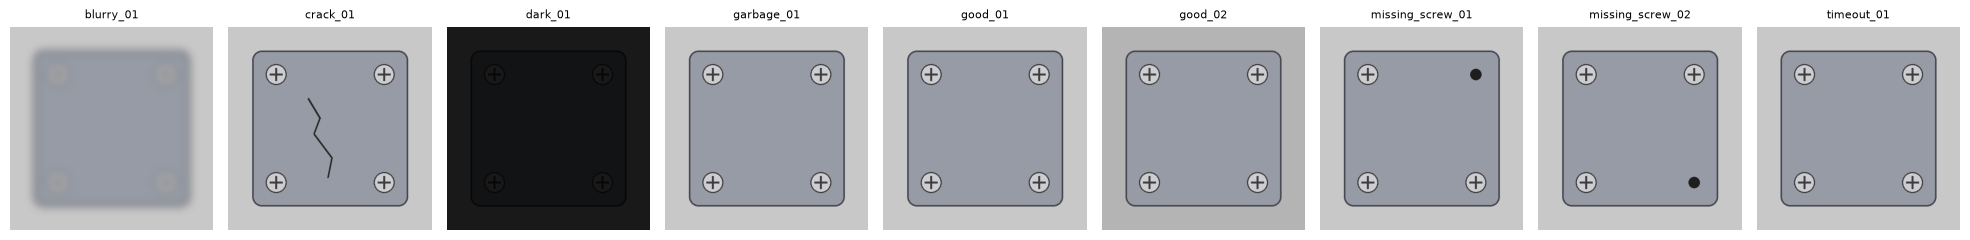

In [14]:
import matplotlib.pyplot as plt
from PIL import Image

files = sorted(Path("samples").glob("*.png"))
fig, axes = plt.subplots(1, len(files), figsize=(2.2 * len(files), 2.6))
for ax, f in zip(axes, files):
    ax.imshow(Image.open(f)); ax.set_title(f.stem, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Run the line (mock model)

One tick of the tree is one part. Every decision carries the reason, which tree leaves ran, and the lane the diverter chose.

In [15]:
import shutil, pandas as pd
from cell import audit

shutil.rmtree("runtime", ignore_errors=True)
cfg = replace(CellConfig(), runtime_dir="runtime")
cell = Cell(cfg, FolderSource(Path("samples")), MockVLM())
tree = build_tree(cell)

parts = []
while cell.stopped is None:
    cell.part = None
    tree.tick()
    if cell.part is not None:
        parts.append(cell.part)
        audit.record_part(cell.runtime, cell.part, "mock")

pd.set_option("display.max_colwidth", 90)
pd.DataFrame({
    "image": [p.image_path.name for p in parts],
    "decision": [p.decision.value for p in parts],
    "lane": [p.lane for p in parts],
    "decided by": [p.decided_by for p in parts],
    "reason": [p.reason for p in parts],
})

,image,decision,lane,decided by,reason
0,blurry_01.png,REVIEW,human review shelf,fallback,image too blurry (sharpness 0 < 30)
1,crack_01.png,REJECT,reject bin,ai+rules,"surface damage at surface center: AI saw ""I see a defect here."""
2,dark_01.png,REVIEW,human review shelf,fallback,image too dark (brightness 21 < 40)
3,garbage_01.png,REVIEW,human review shelf,fallback,AI answer rejected: AI answer for screw top-left has no ANSWER line
4,good_01.png,PASS,pass conveyor,ai+rules,all 9 regions checked and OK
5,good_02.png,PASS,pass conveyor,ai+rules,all 9 regions checked and OK
6,missing_screw_01.png,REJECT,reject bin,ai+rules,"missing screw at screw top-right: AI saw ""I see a defect here."""
7,missing_screw_02.png,REJECT,reject bin,ai+rules,"missing screw at screw bottom-right: AI saw ""I see a defect here."""
8,timeout_01.png,REVIEW,human review shelf,fallback,AI unavailable: model did not answer (simulated timeout)


Every AI answer and every decision lands in an append-only audit log. Below, the leaves visited for three kinds of part:
the AI path for a good part, an early stop for a defect, and a bad photo that never reaches the model.

In [16]:
by_name = {p.image_path.stem: p for p in parts}
for name in ["good_01", "missing_screw_01", "dark_01"]:
    p = by_name[name]
    print(f"{name:18s} {p.decision.value:7s} " + " -> ".join(p.trace))
    print(f"{'':18s} AI calls: {len(p.vlm_raw)}\n")

good_01            PASS    Acquire part -> Image quality OK? -> Model healthy? -> Inspect regions with VLM -> Apply decision rules -> E-stop clear? (pre-actuation) -> Actuate diverter
                   AI calls: 9

missing_screw_01   REJECT  Acquire part -> Image quality OK? -> Model healthy? -> Inspect regions with VLM -> Apply decision rules -> E-stop clear? (pre-actuation) -> Actuate diverter
                   AI calls: 2

dark_01            REVIEW  Acquire part -> Image quality OK? -> Route to human review -> E-stop clear? (pre-actuation) -> Actuate diverter
                   AI calls: 0



### Where the AI looked

Green: the model said OK. Red: the model found a defect. Grey: not checked (a defect stops the check early).
Because the *spec* picks the regions, an operator can always see what the AI was asked and where.

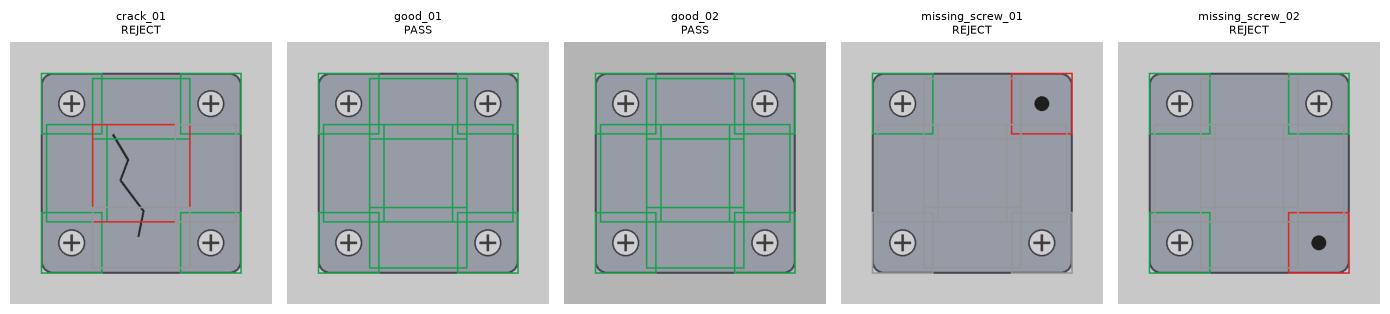

In [17]:
from cell.overlay import draw_regions
from cell.spec import DEFECT_ANSWER

def outcome(p):
    return {r.region: r.answer == DEFECT_ANSWER[r.kind] for r in p.regions}

show = [p for p in parts if p.regions]
fig, axes = plt.subplots(1, len(show), figsize=(2.8 * len(show), 3.2))
for ax, p in zip(axes, show):
    ax.imshow(draw_regions(p.image_path, outcome(p)))
    ax.set_title(f"{p.image_path.stem}\n{p.decision.value}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. What can go wrong, and what the cell does about it

### 5a. The model's answer is never trusted as-is
The validator needs a description *and* exactly one allowed word for that kind of region. Anything else is rejected and the
part goes to a human.

In [18]:
from cell.spec import PART_SPEC
from cell.validator import ValidationError, parse_region_answer

screw = next(r for r in PART_SPEC if r.kind == "screw")
surface = next(r for r in PART_SPEC if r.kind == "surface")
cases = [
    ("good answer",            "A screw head is installed.\nANSWER: SCREW", screw),
    ("empty reply",            "", screw),
    ("no ANSWER line",         "The part is fine.", screw),
    ("word not allowed",       "A screw.\nANSWER: MAYBE", screw),
    ("wrong region vocabulary","A clean surface.\nANSWER: SCREW", surface),
    ("answer, no evidence",    "ANSWER: SCREW", screw),
]
rows = []
for label, raw, region in cases:
    try:
        r = parse_region_answer(raw, region)
        rows.append((label, "ACCEPTED", f"{r.answer}: {r.description}"))
    except ValidationError as e:
        rows.append((label, "REJECTED -> human", str(e)))
pd.DataFrame(rows, columns=["case", "validator", "detail"])

,case,validator,detail
0,good answer,ACCEPTED,SCREW: A screw head is installed.
1,empty reply,REJECTED -> human,AI gave an empty answer for screw top-left
2,no ANSWER line,REJECTED -> human,AI answer for screw top-left has no ANSWER line
3,word not allowed,REJECTED -> human,"AI answered 'MAYBE' for screw top-left, expected one of ('SCREW', 'EMPTY')"
4,wrong region vocabulary,REJECTED -> human,"AI answered 'SCREW' for surface top, expected one of ('CLEAN', 'DAMAGED')"
5,"answer, no evidence",REJECTED -> human,AI gave no description for screw top-left


### 5b. E-stop during the slow AI step
The e-stop is checked again just before the diverter. The decision is logged, but the gate does not move.

In [19]:
class EStopWhileThinking(MockVLM):
    def inspect(self, image_path, region):
        c.estop_file.parent.mkdir(parents=True, exist_ok=True)
        c.estop_file.touch()          # operator hits e-stop while the model is busy
        return super().inspect(image_path, region)

c = Cell(replace(CellConfig(), runtime_dir="runtime_estop"), FolderSource(Path("samples")), EStopWhileThinking())
c.source.images = [Path("samples/crack_01.png")]
t = build_tree(c); c.part = None; t.tick()
print("decision:", c.part.decision.value, "| lane:", c.part.lane, "(None = diverter never moved)")
shutil.rmtree("runtime_estop", ignore_errors=True)

decision: REJECT | lane: None (None = diverter never moved)


### 5c. Dead model: the circuit breaker
A failing model can cost a full timeout per part. After 3 failures in a row the cell stops waiting on it,
sends parts to human review, and probes the model every 5th part.

In [20]:
calls = []
class DeadModel(MockVLM):
    def inspect(self, image_path, region):
        calls.append(image_path)
        return MockVLM.inspect(self, Path("samples/timeout_01.png"), region)

c = Cell(replace(CellConfig(), runtime_dir="runtime_cb", max_consecutive_vlm_failures=2, probe_every_n_parts=3),
         FolderSource(Path("samples")), DeadModel())
c.source.images = [Path("samples/good_01.png")] * 9
t = build_tree(c)
ps = []
while c.stopped is None:
    c.part = None; t.tick()
    if c.part is not None: ps.append(c.part)
print(f"{len(ps)} parts, {len(calls)} model calls (naive loop would make {len(ps)})")
print("decisions:", {p.decision.value for p in ps})
print("part 3 reason:", ps[2].reason)
shutil.rmtree("runtime_cb", ignore_errors=True)

9 parts, 4 model calls (naive loop would make 9)
decisions: {'REVIEW'}
part 3 reason: degraded mode: AI failed 2 times in a row, skipping it


### 5d. Operator override
The AI-path decision is never overwritten. The override is a separate record with the operator's name.

In [21]:
garbage = next(p for p in audit.load_parts(Path("runtime")) if "garbage" in p["image_path"])
print("before:", garbage["final_decision"], "|", garbage["reason"])
audit.record_override(Path("runtime"), garbage["part_id"], "PASS", "Sam", "checked by hand")
after = next(p for p in audit.load_parts(Path("runtime")) if p["part_id"] == garbage["part_id"])
print("after: ", after["final_decision"], "| AI path said:", after["decision"], "| override by:", after["override"]["operator"])

before: REVIEW | AI answer rejected: AI answer for screw top-left has no ANSWER line
after:  PASS | AI path said: REVIEW | override by: Sam


## 6. Safety tests

The project's test suite, run against the code above.

In [22]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "--rootdir", ".", "tests"],
                   capture_output=True, text=True, env={**os.environ, "PYTHONPATH": "."})
print(r.stdout[-1500:], r.stderr[-500:])

..................                                                       [100%]
18 passed in 4.35s
 


## 7. Why the AI only sees close-ups (what we learned about the model)

These come from the author's runs of Gemma 3 4B on a laptop CPU through Ollama, on the project's synthetic parts. They are
recorded observations, not something this notebook re-runs, and the part images are synthetic, so treat them as
design evidence rather than a benchmark.

| Approach | Result with Gemma 3 4B on CPU |
|---|---|
| Whole part, "is it defective?" with confidence | Said a part with a **missing screw** was fine at **95% confidence**; missed the crack |
| Whole part, check each corner | Said all 4 screws present on every image |
| Close-up per corner, forced JSON answer | Same answer for every crop, right or wrong |
| **Close-up per region, describe first, then answer** | **Used in the final cell; measured below** |

So: self-reported confidence is not used anywhere, the deterministic side decides where to look, and the model must describe
before it answers.

### Measured run of the final cell (real Gemma 3 4B via local Ollama, 2026-11-12)

Hardware: Intel laptop, Windows 11, 7.7 GB RAM, CPU only. Limit: 600 s per close-up. Full log: `results/gemma_samples_run.md`.

| Part | Expected | Cell decision | Model's words at the deciding region |
|---|---|---|---|
| good_01 | PASS | **PASS** (9/9 regions OK) | "smooth and uniform with no visible lines, cracks, scratches, or marks" |
| missing_screw_01 | REJECT top-right | **REJECT at screw top-right** (2 close-ups) | "a circular, black hole in the center" |
| crack_01 | REJECT | **REJECT at surface top** | "several fine lines and scratches" |

3/3 decisions correct; 16/16 answers passed the validator; 10/10 screw answers correct. The crack was flagged in the
region holding its upper tip rather than the centre, so treat that one as a correct decision with weak evidence. Close-ups
took 12-238 s (median 138 s) because this laptop is short of RAM. With the default 120 s limit, every call timed out, and
the cell sent all 9 parts to human review via the circuit breaker: the fault path, working on real hardware.

### Trade-offs

| Choice | Why | What we gave up |
|---|---|---|
| Gemma 3 4B (open weights, Ollama) | Takes images, runs quantised in about 3.3 GB on an 8 GB laptop CPU, no cloud, explains its answer in words | Slower than a trained detector |
| VLM, not a trained CNN | No labelled defect set; a new part is a spec edit; plain-English reasons | Throughput; accuracy must be proven per part |
| Behaviour tree, not a state machine | The Selector gives "AI path, else human" structurally; reads as a diagram; e-stop re-checked every tick; standard in robot stacks | One extra library |
| Model confidence ignored | It was meaningless (95% on a wrong answer) | Decisions rest on fixed rules only |

## 8. Deployment: on-device, offline

| Node | Runs | Network |
|---|---|---|
| Inspection workstation | behaviour tree, Gemma 3 4B via Ollama, dashboard server | model at `localhost` only |
| Operator tablet (optional) | browser on the dashboard | local LAN only |

**Why fully local, not hybrid:** the model makes one narrow judgement on every part. A cloud call would add latency and a
Wi-Fi dependency to that decision, and part images can be customer IP. **Connectivity drops:** plant Wi-Fi down changes
nothing; a tablet disconnect leaves the line running with all its safety behaviour, because the dashboard is a separate
process; a model server that dies trips the circuit breaker shown in 5c.

### Real model run

If an Ollama server with `gemma3:4b` is reachable, this cell runs the same tree with the real model on the missing-screw
part (2 close-ups). The full measured run is in section 7. On Kaggle there is normally no Ollama, so it skips cleanly. Nothing here calls a
hosted API: the only network address is `localhost`.

In [23]:
import requests
from cell.vlm import OllamaVLM

# 600 s per close-up: on an 8 GB CPU-only laptop a new close-up can take minutes.
cfg = replace(CellConfig(), runtime_dir="runtime_live", vlm_timeout_s=600)
try:
    tags = requests.get(f"{cfg.ollama_url}/api/tags", timeout=2).json()
    have = any(m["name"].startswith(cfg.model) for m in tags.get("models", []))
except Exception:
    have = False

if not have:
    print(f"No local Ollama with {cfg.model} found: skipping the live run.")
    print("To run it on your machine:  ollama pull gemma3:4b   then re-run this notebook locally.")
else:
    vlm = OllamaVLM(cfg)
    live = Cell(cfg, FolderSource(Path("samples")), vlm)
    live.source.images = [Path("samples/missing_screw_01.png")]  # 2 close-ups: quick
    print(f"warm-up: {vlm.warm_up():.0f}s")
    lt = build_tree(live)
    while live.stopped is None:
        live.part = None; lt.tick()
        if live.part is not None:
            p = live.part
            print(f"{p.image_path.name:22s} {p.decision.value:7s} {p.vlm_latency_s}s  {p.reason}")
            for r in p.regions:
                print(f"    {r.region:18s} {r.answer:7s} {r.description}")
    shutil.rmtree("runtime_live", ignore_errors=True)

warm-up: 55s


missing_screw_01.png   REJECT  205.57s  missing screw at screw top-right: AI saw "I see a gray metal plate with a circular, black hole in the center."
    screw top-left     SCREW   I see a gray metal plate with a white plus sign (+) symbol representing a screw head positioned in a circular outline.
    screw top-right    EMPTY   I see a gray metal plate with a circular, black hole in the center.


## 9. Limits and what comes next

* Regions are fractions of the frame, so the cell assumes a fixed camera and a jig. The coordinates in `cell/spec.py` fit the
  synthetic 512 px parts and must be re-fitted to real photos.
* The sample parts are synthetic. Results on real parts have not been measured here.
* 12-238 s per close-up on an 8 GB CPU-only laptop. More RAM or a GPU brings that to seconds; the tree and rules do not change.
* The real-model run covers 3 synthetic parts (16 close-ups): evidence the pipeline works, not an accuracy benchmark.
* The diverter is simulated. `ActuateDiverter` is the one leaf to swap for a PLC write or robot motion routine.
* `MockVLM` is not an inspector. It only proves the control logic.

The operator dashboard (`dashboard.py`, Streamlit) shows the live part, the review queue with override buttons, the history,
and a software e-stop. It runs as a separate process and shares only files with the line, so a dashboard crash cannot
affect the line's safety behaviour.